# Real Lorentz TEM: magnetic/electrostatic phase and projected induction


## 1. Problem

Infer separated magnetic/electrostatic phase and two projected induction components from real opposite-orientation Lorentz-TEM focal series. The selected experimental island-array example is distinct from the paper's Pt/Co/W specimen.

This review actively reconstructs two real aligned focal series of an artificial-spin-ice island array. The data are the original authors’ existing experimental demo, not the separate Pt/Co/W example in the 2021 paper. A native 512×512 central crop preserves 5.1066 nm pixels; the exterior field is discarded. Both specimen orientations and all seven defocus planes are public observations. There is no independently measured phase/induction truth or independently calibrated thickness.

The exit waves have phases φE+φB and φE−φB. In the **lens-defocus** convention the near-focus intensity derivative is +λ/(2π) div(I0 gradφ), opposite the free-space propagation coordinate. Equal-flux normalized central focus differences are combined by half-sum/half-difference to isolate electrostatic/magnetic contributions. Two inverse Laplacians, divided by common in-focus intensity between them, give the original Teague TIE estimate. The zero-frequency mode is unobservable; each reported phase has minimum zero. Both phases are radians.

Projected induction is Bx=(ℏ/e)∂yφB and By=−(ℏ/e)∂xφB. Here x increases by column and y by row, both in the plotted detector coordinates. Units are **T·nm**, representing ∫B dz including stray fields. No guessed thickness converts this to local B or magnetization. The independent coherent-wave test fixes sign and units; exact-backend original/local parity tests do not replace that physical check.


## 2. Data

Both aligned orientations and all seven defocus planes are public; the native 512 by 512 crop retains 5.1066 nm pixels. Intensities are detector observations, phases radians and induction T nm. Thickness and true phase/induction are independently unknown.

These are existing real experimental LTEM intensity observations. The supplied crop preserves native pixels, with no spatial resizing, and both specimen orientations are already aligned into the same image coordinates.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| unflipped | (1, 7, 512, 512) | float32 | Aligned unflipped focal series, arbitrary detector intensity units |
| flipped | (1, 7, 512, 512) | float32 | Aligned inverted-specimen focal series, arbitrary detector intensity units |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Pixel pitch | 5.1066 | nm/pixel | Same pitch along rows and columns |
| Accelerating voltage | 200000 | V | Relativistic electron wavelength calibration |
| Defocus planes, in array order | -928972, -398131, -199065, 0, 199065, 398131, 928972 | nm | Signed lens defocus, common to both series |
| Native source image size | 2048 × 2048 | pixel | Original aligned acquisition field |
| Crop | rows 768:1280, columns 768:1280 | pixel | Zero-based, stop-exclusive native central ROI |
| Coordinate origin | upper-left pixel center | pixel | Columns increase rightward, rows downward |
| Physical field width | 2614.5792 | nm | 512 pixel pitches |
| Specimen inversion | magnetic phase changes sign | dimensionless | Flipped images are already spatially registered |
| Boundary convention | periodic finite ROI | dimensionless | Unknown exterior is discarded; boundary choice limits quantitative accuracy |
| Aperture bandwidth | circular radius N/3 for N=512 | cycles per field | Fixed reciprocal-space support for transport reconstruction |
| Noise | measured, no calibrated variance supplied | arbitrary intensity units | No noiseless observation or independently known phase is supplied |


In [1]:
%matplotlib inline
import os,sys,time,json,importlib.util
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').is_dir(): root=root.parent
assert (root/'src').is_dir()
sys.path.insert(0,str(root))
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src.visualization import review_figures
unflipped,flipped=load_observations(root/'data/raw_data.npz')
print('Real observations:',unflipped.shape,unflipped.dtype,'per orientation')
print('Pixel pitch 5.1066 nm; voltage 200000 V; nearest defocus ±199065 nm')

Real observations: (7, 512, 512) float32 per orientation
Pixel pitch 5.1066 nm; voltage 200000 V; nearest defocus ±199065 nm


## 3. Physics

The lens-defocus convention is $\partial_zI=+\lambda\nabla\cdot(I_0\nabla\phi)/(2\pi)$, with intensity $I$, focus intensity $I_0$, electron wavelength $\lambda$, phase $\phi$ and lens defocus $z$. Half-sum/difference separate phases $\phi_E\pm\phi_B$. Projected induction obeys $B_x=(\hbar/e)\partial_y\phi_B$, $B_y=-(\hbar/e)\partial_x\phi_B$ with the stated detector axes.

The observations are two aligned focal series of an artificial spin-ice island array, acquired before and after specimen inversion. At the exit surface the wave is


$$
\psi_\pm(x,y)=\sqrt{I_0(x,y)}\exp\bigl(i[\phi_E(x,y)\pm\phi_B(x,y)]\bigr).
$$


Here x is the image column coordinate, y is the row coordinate, I0 is in-focus intensity, and the real phases φE and φB are respectively electrostatic and magnetic contributions in radians. The plus sign denotes the unflipped series. In the lens-defocus convention used by these observations, the coherent transfer at spatial frequency k is exp(iπλdf|k|²), where λ is electron wavelength and df is signed lens defocus. Its near-focus transport relation is


$$
\frac{\partial I_\pm}{\partial d_f}
=\frac{\lambda}{2\pi}\nabla\cdot
\left[I_0\nabla(\phi_E\pm\phi_B)\right].
$$


Spatial derivatives here use physical image coordinates. Positive lens defocus is opposite positive free-space propagation distance. Illumination gain can differ between focal planes, and finite focus separation, noise, specimen edges and unobserved exterior fields limit the transport approximation. Both phases have an unobservable additive constant. Use the fixed convention that each phase has minimum zero over the complete supplied ROI, with no subsequent fit or alignment.


## 4. Method

The local Teague inverse uses two inverse Laplacians with intensity division, zero-frequency removal, nearest-focus difference and source circular cutoff. Minimum-zero phase fixes only the unobservable additive gauge. Alternative focus pairs, Tikhonov filtering and mirrored boundaries are freshly computed sensitivities.

Transport-of-intensity inversion with two inverse Laplacians can separate magnetic and electrostatic phase by taking the difference and sum of the two focus derivatives. Equalizing integrated image intensity handles illumination gain variation. The zero spatial frequency cannot determine the phase constant. Fourier regularization and a physically stated boundary convention help control amplification of low-frequency uncertainty. Different focus separations and mirrored boundary extensions provide useful sensitivity checks rather than independent truth.


## 5. Results

Preserve all phase/induction separation, vectors, original/local numerical comparison, independent transport residuals and focus/boundary/filter sensitivity. The backend ULP discrepancy and its exact-backend resolution are numerical provenance, not a new physical correction.

### Active standard reconstruction and scientific comparisons

The standard reconstruction uses the nearest focus pair, periodic finite-ROI boundaries, zero-frequency removal and the source circular frequency cutoff. Optional source Tikhonov filtering and mirrored boundaries are evaluated as actual new calculations. The double-Poisson implementation retains the source's centered periodic stencils; their high-frequency attenuation is tested analytically. Induction uses centered interior derivatives with second-order one-sided edge formulas.

The upstream notebook's task-relevant TIE comparisons are retained: magnetic/electrostatic separation, induction vectors, focus-pair choice, regularization and boundary extension. Its separate single-image CGT SITIE example has a different specimen/acquisition and is outside this task. Every curve and map below labeled fresh comes from a reconstruction executed here.

### Data, original-code parity, field maps and observation residuals

The original comparison is an independently executed **unchanged original implementation on these exact observations**, not a paper figure or cached upstream notebook. Its code revision, source/data hashes and environment are in validation. A separate NumPy1.26 rerun exposed 1–2 ULP float32 image-sum differences; the exact NumPy2.4.6 backend eliminates that numerical discrepancy. Original estimates are method references, never truth.

Figure 4 independently differentiates the recovered phases spectrally in nm coordinates and compares λ/(2π)div(I0 gradφ) with the measured half-sum/half-difference divided by 2df. It applies no contrast fit, alignment or hidden image mask. Nonzero residuals are meaningful: finite defocus, circular bandwidth cutoff, centered-gradient attenuation, periodic ROI closure and the nonuniform-intensity auxiliary-potential approximation all limit transport consistency. Figure 5 uses a shared T·nm color scale, so changing defocus, low-frequency filtering or boundary assumptions remains visible.


In [2]:
start=time.perf_counter()
fresh=reconstruct(unflipped,flipped)
standard_seconds=time.perf_counter()-start
comparisons={}
timings={'standard':standard_seconds}
for name,kwargs in [('df398.131um',{'index':1}),('df928.972um',{'index':2}),('even boundary',{'symmetric':True}),('qc0.0002',{'qc':.0002}),('qc0.0005',{'qc':.0005}),('qc0.001',{'qc':.001})]:
    start=time.perf_counter();comparisons[name]=reconstruct(unflipped,flipped,**kwargs);timings[name]=time.perf_counter()-start
with np.load(root/'notebooks/reference_outputs/upstream_methods.npz',allow_pickle=False) as z:
    upstream={key:z[key] for key in ['phase_B','phase_E','Bx','By']}
print('Fresh CPU runtimes (s):',json.dumps(timings,indent=2))
submission=root/'output/reconstruction.npz';submission.parent.mkdir(exist_ok=True)
np.savez_compressed(submission,**{key:fresh[key][None].astype(np.float64) for key in ['phase_B','phase_E','Bx','By']})

Fresh CPU runtimes (s): {
  "standard": 0.10813960000086809,
  "df398.131um": 0.11173080000298796,
  "df928.972um": 0.11257150000164984,
  "even boundary": 0.5241519999981392,
  "qc0.0002": 0.10999440000159666,
  "qc0.0005": 0.11238750000484288,
  "qc0.001": 0.1095564999995986
}


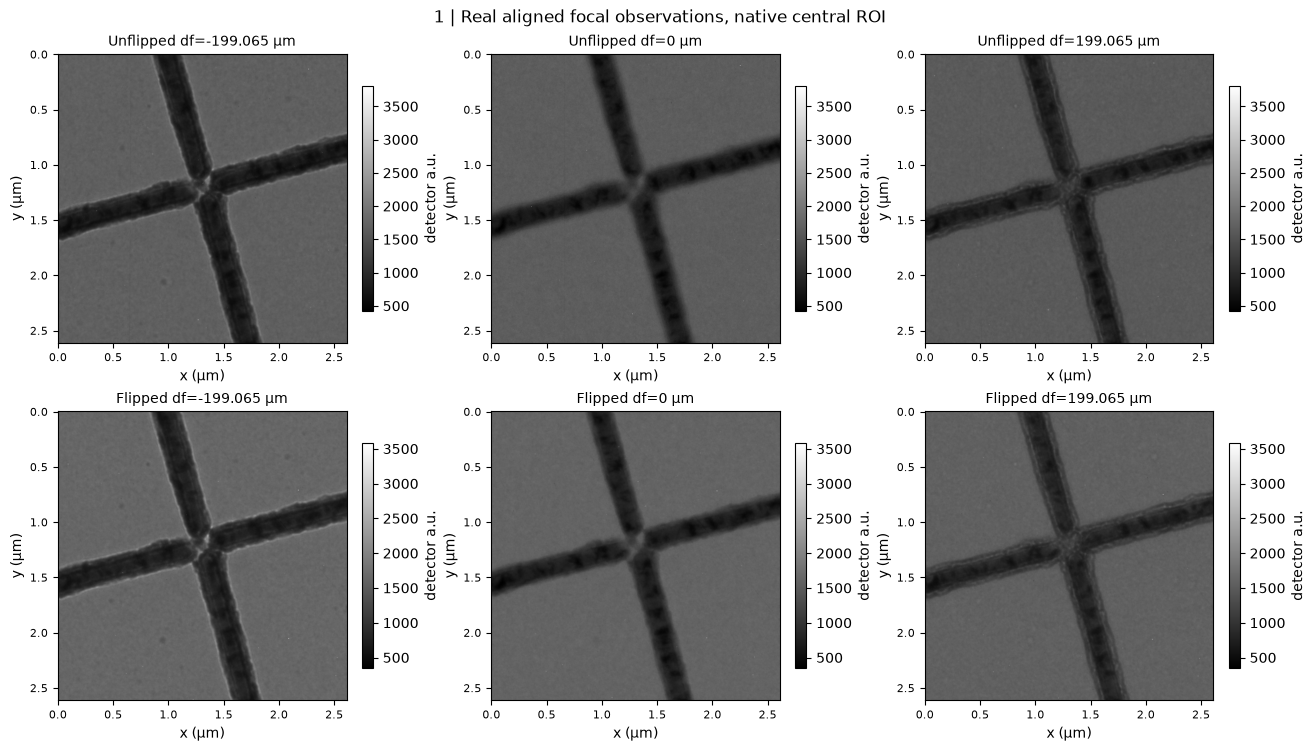

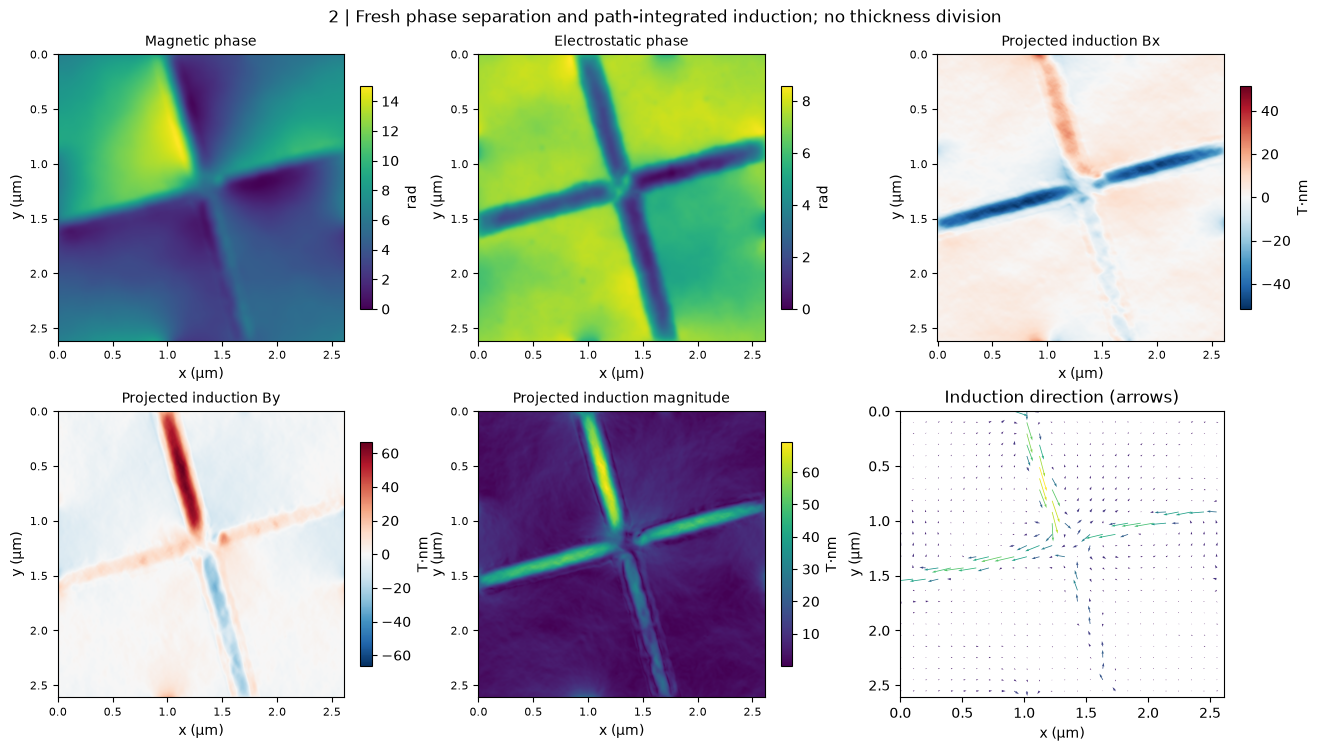

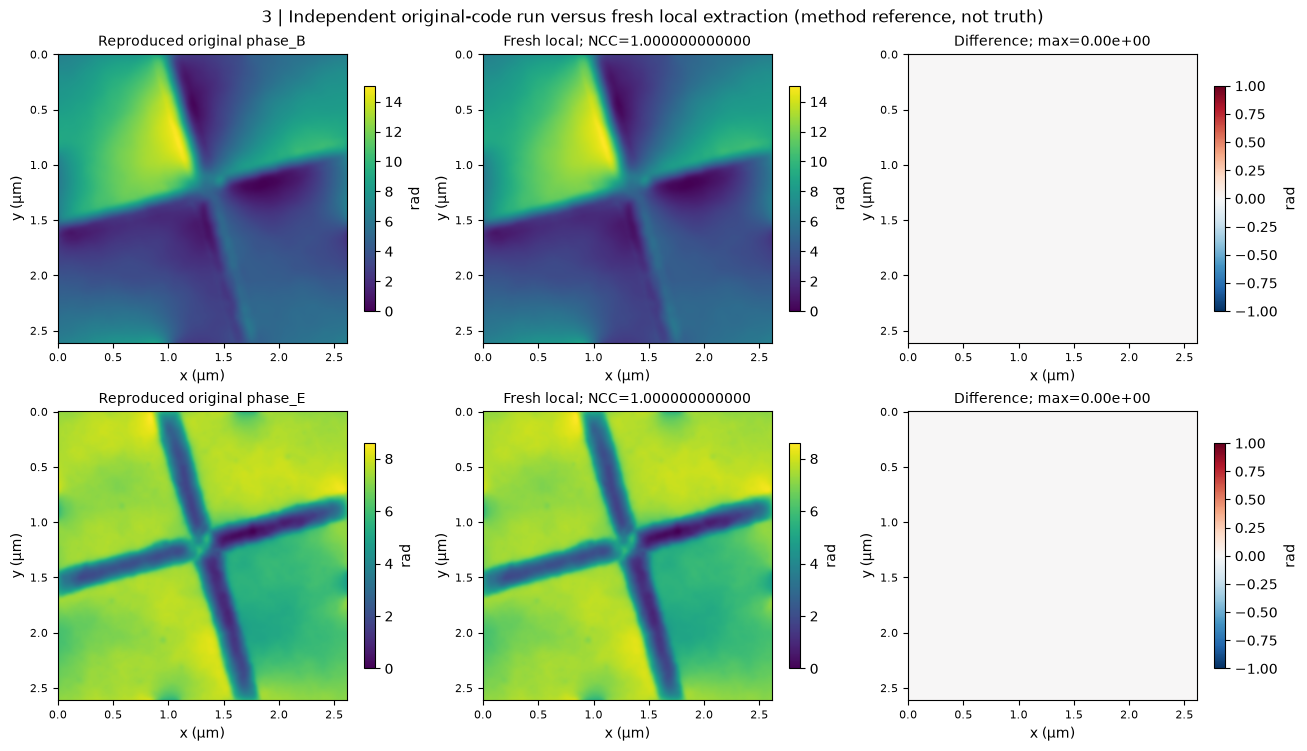

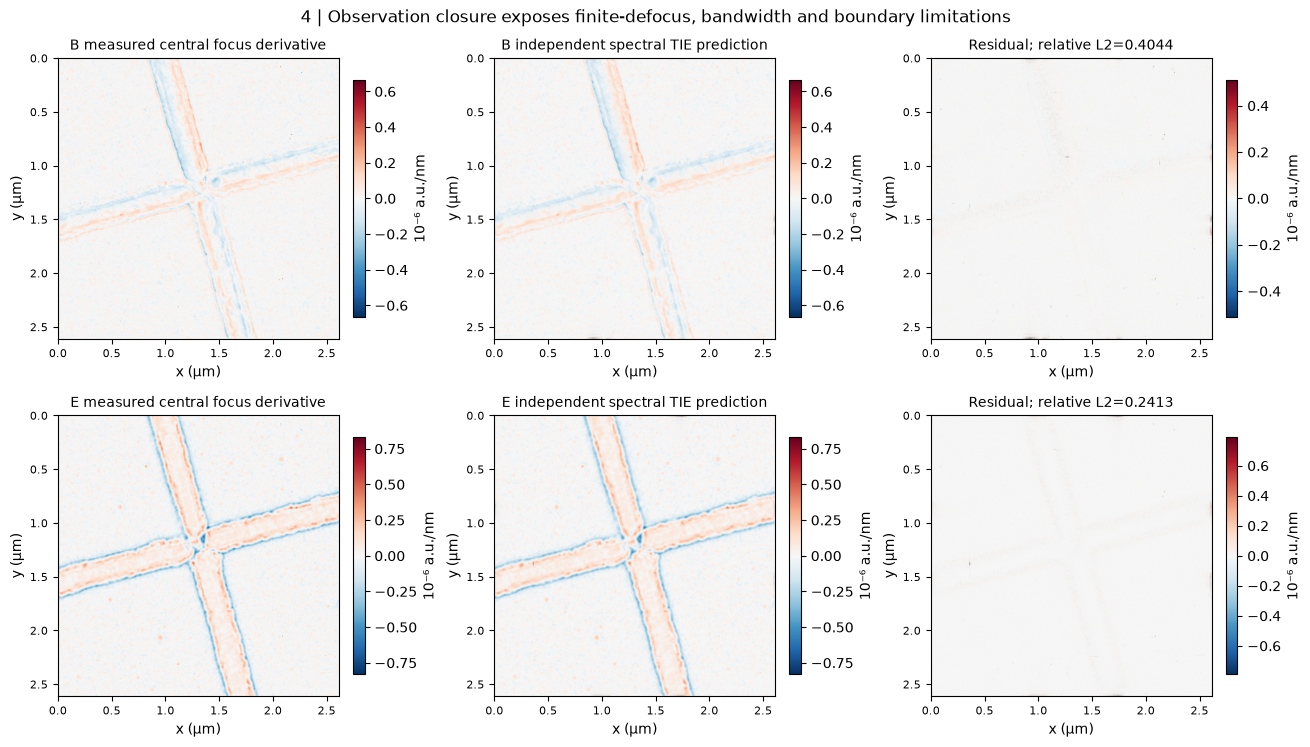

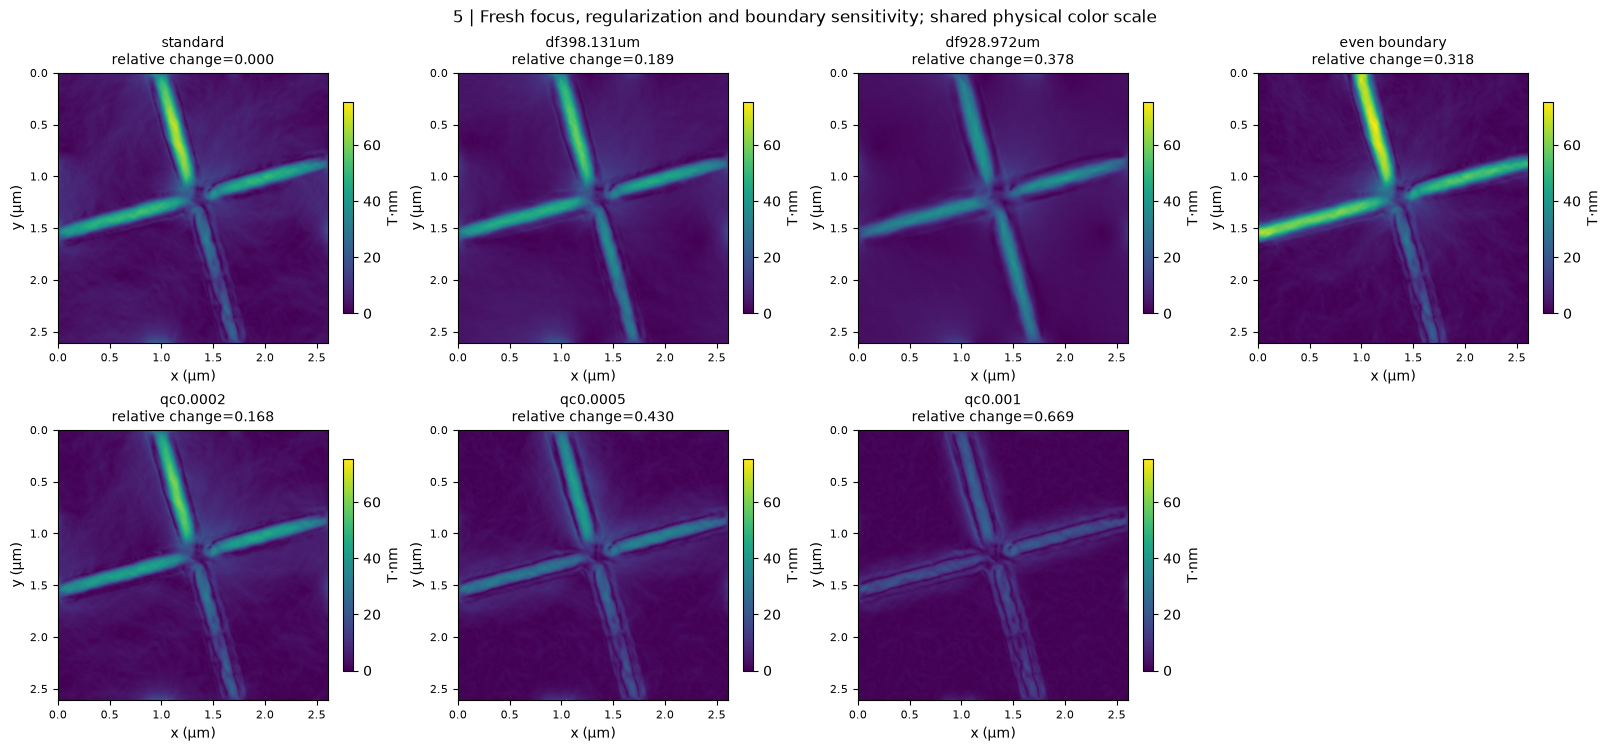

{
  "comparison_to_original": {
    "phase_B": {
      "ncc": 1.0,
      "nrmse": 0.0
    },
    "phase_E": {
      "ncc": 1.0,
      "nrmse": 0.0
    },
    "Bx": {
      "ncc": 0.9999999999999998,
      "nrmse": 3.6782169715487465e-16
    },
    "By": {
      "ncc": 1.0000000000000002,
      "nrmse": 3.1757243048844493e-16
    }
  },
  "observation_relative_l2": {
    "B": 0.4044319516081601,
    "E": 0.24133229954390936
  },
  "comparisons": {
    "standard": {
      "magnitude_relative_change": 0.0,
      "peak_T_nm": 69.19535620236515
    },
    "df398.131um": {
      "magnitude_relative_change": 0.1894825042049427,
      "peak_T_nm": 58.783291424641014
    },
    "df928.972um": {
      "magnitude_relative_change": 0.3776352129669151,
      "peak_T_nm": 41.8294811969313
    },
    "even boundary": {
      "magnitude_relative_change": 0.31775758595670034,
      "peak_T_nm": 75.18958888201759
    },
    "qc0.0002": {
      "magnitude_relative_change": 0.1681920074653732,
      "peak

In [3]:
figure_dir=Path(os.environ.get('IMAGING_FIGURE_DIR',root/'output/review_figures'))
figures,figure_metrics=review_figures(unflipped,flipped,fresh,upstream,comparisons,figure_dir)
for fig in figures: display(fig);plt.close(fig)
print(json.dumps(figure_metrics,indent=2))
print('Actual PNG/SVG/PDF groups and exact numeric sources:',figure_dir)

In [4]:
spec=importlib.util.spec_from_file_location('lorentz_standalone_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(submission)
print(json.dumps(report,indent=2));assert exit_code==0
print('Fresh standard reconstruction runtime:',standard_seconds,'s')
print('Limitations: unknown exterior/boundary flux; no independent phase or induction truth; finite-defocus TIE approximation; no local magnetization or thickness inference.')

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "phase_B_ncc": 1.0,
    "phase_B_nrmse": 0.0,
    "phase_E_ncc": 1.0,
    "phase_E_nrmse": 0.0,
    "Bx_ncc": 0.9999999999999998,
    "Bx_nrmse": 3.6782169715487465e-16,
    "By_ncc": 1.0000000000000002,
    "By_nrmse": 3.1757243048844493e-16,
    "observation_B": 0.4044319516081601,
    "observation_E": 0.24133229954390936,
    "induction_consistency": 0.0
  },
  "thresholds": {
    "phase_B_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "phase_B_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "phase_E_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "phase_E_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "Bx_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "Bx_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "By_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "By_n

## 6. Conclusion

The retained coherent-wave check supports physical sign and units while method agreement supports extraction. Finite defocus, centered stencils, cropped periodic boundaries and auxiliary-potential assumptions limit accuracy. Without thickness, T nm must not be converted to a local magnetic field or magnetization.

### Independent evaluation and interpretation

All four required arrays are evaluated without alignment using cosine NCC and RMS error normalized by reference dynamic range. A nonzero numerical tolerance is justified by independently executed backend variation, not perfect self-comparison. Additional metrics constrain both physical observation derivatives and induction/phase consistency. A valid standard-method match does not establish true field accuracy. Boundary and focus sensitivity are scientifically relevant uncertainties, especially when a cropped ROI omits surrounding magnetic flux.
